# ST1131 Introduction to Statistics and Statistical Computing
## Topic 8 (Hypothesis Testing)

In the lecture, we learnt the five steps of a hypothesis test, and how to test a population proportion, a population mean, and the difference between two population means. In this notebook, we will use Python to compute test statistics and $p$-values, carry out each test with a single function from `scipy.stats`, check the normality assumption with QQ plots and the Shapiro-Wilk test, and use simulation to see what Type I errors and power really mean.

Every test in this topic follows the same five steps:

1. Check assumptions
2. State hypotheses
3. Test statistic
4. $p$-value
5. Conclusion

Python helps us with Steps 3 and 4. Steps 1, 2 and 5 still need our own judgement.

## Packages

Besides `norm` and `t` from Topic 7, we import several testing functions from `scipy.stats`. Each one will be introduced when we first use it. If you do not wish to import them individually, you can import `stats` from `scipy` and then add `stats.` at the front of those functions later when using them.

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t
from scipy.stats import ttest_1samp, ttest_ind, ttest_rel, levene, shapiro, probplot

As in Topic 7, we must not create a variable called `t`, since that would replace the $t$-distribution.

## Test for a population proportion

For $H_0: p=p_0$, the test statistic is

$$Z=\frac{\hat{p}-p_0}{\sqrt{p_0(1-p_0)/n}},$$

and the null distribution is $N(0,1)$. The test is valid when $np_0(1-p_0)\ge5$. Notice that the standard error uses $p_0$, the value under $H_0$, and not $\hat{p}$ as in the confidence interval of Topic 7.

The $p$-value depends on the side of the test:

| $H_1$ | $p$-value | Python |
|---|---|---|
| $p>p_0$ | right area of $Z$ | `norm.sf(z)` |
| $p<p_0$ | left area of $Z$ | `norm.cdf(z)` |
| $p\neq p_0$ | two tail areas | `2*norm.sf(abs(z))` |

For a two-sided test, we double the area beyond $|Z|$, since a value just as far from 0 on the other side is equally extreme. Using `abs(z)` makes this work whether $Z$ is positive or negative.

### Election example

In a random sample of $n=3889$ voters, $\hat{p}=0.531$ voted for Brown. We want to know if Brown will win, so $H_0: p=0.5$ against $H_1: p>0.5$.

In [73]:
n = 3889
p_hat = 0.531
p0 = 0.5

print(f"n*p0*(1-p0): {n*p0*(1-p0)}") #Step 1: should be at least 5

se = np.sqrt(p0*(1-p0)/n) #standard error under H0
z = (p_hat-p0)/se #Step 3: test statistic
p_value = norm.sf(z) #Step 4: right-sided, so the area to the right of z

print(f"Test statistic: {round(z, 3)}")
print(f"p-value: {p_value}")

n*p0*(1-p0): 972.25
Test statistic: 3.866
p-value: 5.521904600425912e-05


The $p$-value is printed as `5.52e-05`, which is scientific notation for $5.52\times10^{-5}=0.0000552$. The lecture gives $5.53\times10^{-5}$ because it rounds $Z$ to 3.866 first.

Since the $p$-value is less than 0.001, we have strong evidence against $H_0$, and we conclude that Brown will likely win the election. At $\alpha=0.05$, we reject $H_0$.

### $p$-values as areas

To see what a $p$-value is, let's use a smaller poll. Suppose 16 of $n=23$ randomly chosen voters support a candidate, and we test $H_0: p=0.5$. The condition holds since $23\times0.5\times0.5=5.75\ge5$.

In [74]:
n = 23
p_hat = 16/23
p0 = 0.5

z = (p_hat-p0)/np.sqrt(p0*(1-p0)/n)
print(f"Test statistic: {round(z, 4)}")
print(f"Right-sided p-value: {round(norm.sf(z), 4)}")
print(f"Two-sided p-value: {round(2*norm.sf(abs(z)), 4)}")

Test statistic: 1.8766
Right-sided p-value: 0.0303
Two-sided p-value: 0.0606


The $p$-value is the area under the null distribution $N(0,1)$ that is as extreme as, or more extreme than, our test statistic.

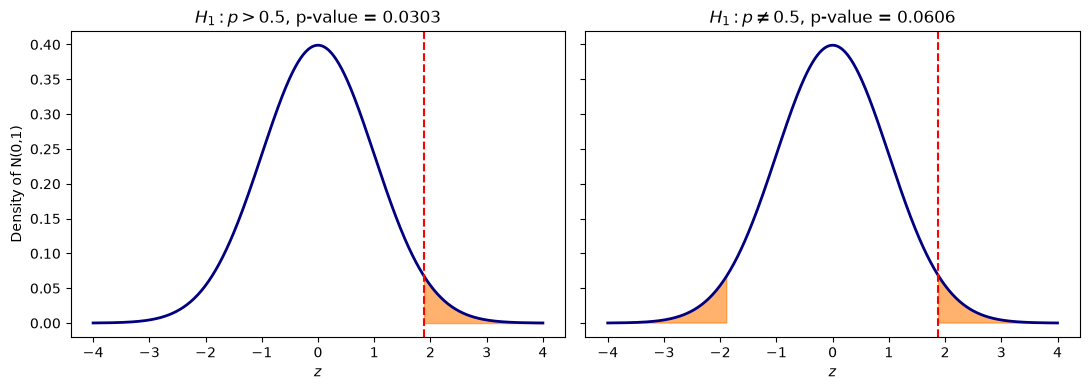

In [46]:
xs = np.linspace(-4,4,500)
fx = norm.pdf(xs)

fig, axes = plt.subplots(1, 2, figsize=(11,4), sharey=True)

axes[0].plot(xs, fx, color="navy", linewidth=2)
axes[0].fill_between(xs, fx, where=(xs >= z), color="tab:orange", alpha=0.6)
axes[0].set_title(rf"$H_1: p>0.5$, p-value = {norm.sf(z):.4f}")

axes[1].plot(xs, fx, color="navy", linewidth=2)
axes[1].fill_between(xs, fx, where=(xs >= abs(z)) | (xs <= -abs(z)), color="tab:orange", alpha=0.6)
axes[1].set_title(rf"$H_1: p\neq 0.5$, p-value = {2*norm.sf(abs(z)):.4f}")

for ax in axes:
    ax.axvline(z, color="red", linestyle="--")
    ax.set_xlabel(r"$z$")
axes[0].set_ylabel("Density of N(0,1)")
plt.tight_layout()
plt.show()

The red dashed line is the observed test statistic. The symbol `|` in the second `where` means "or", so both tails are shaded. At $\alpha=0.05$, the right-sided test rejects $H_0$, but the two-sided test does not, since its $p$-value is twice as large. This is why the side of the test must be decided in Step 2, before looking at the data.

## Test for a population mean (one-sample $t$-test)

For $H_0: \mu=\mu_0$, the test statistic is

$$T=\frac{\bar{X}-\mu_0}{s/\sqrt{n}},$$

and the null distribution is $t_{n-1}$. The $p$-values work the same way as before, using `t.sf` and `t.cdf` with `df=n-1`.

### Gentoo penguins example

A random sample of $n=123$ Gentoo penguins has mean bill length $\bar{X}=47.5$ mm and standard deviation $s=3.08$ mm. We test whether their mean bill length differs from that of Adelie penguins, 38.8 mm, so $H_0: \mu=38.8$ against $H_1: \mu\neq38.8$.

In [47]:
penguins = pd.read_csv("../data/billlength_Gentoo.csv")
length = penguins["length"]
n = len(length)
x_bar = np.mean(length)
s = np.std(length, ddof=1)
mu0 = 38.8

se = s/np.sqrt(n)
T = (x_bar-mu0)/se
p_value = 2*t.sf(abs(T), df=n-1) #two-sided

print(f"Standard error: {round(se, 3)}")
print(f"Test statistic: {round(T, 2)}")
print(f"p-value: {p_value}")

Standard error: 0.278
Test statistic: 31.33
p-value: 3.518227530169631e-60


The sample mean is 31.3 standard errors away from 38.8, and the $p$-value is practically 0. The data provide extremely strong evidence that the mean bill length of Gentoo penguins differs from 38.8 mm.

### Working with raw data: `ttest_1samp`

When we have the data itself, `ttest_1samp(data, popmean)` does Steps 3 and 4 in one go. The `alternative` argument sets the side of the test: `"two-sided"` (the default), `"greater"` or `"less"`.

Since we have already read the penguins data, we can pass `length` straight to `ttest_1samp`.

In [48]:
result = ttest_1samp(length, popmean=38.8, alternative="two-sided")
print(f"Test statistic: {round(result.statistic, 2)}")
print(f"p-value: {result.pvalue}")

Test statistic: 31.33
p-value: 3.518227530169631e-60


This gives the same test statistic and $p$-value as our step-by-step calculation above. The result stores the test statistic, the $p$-value and the degrees of freedom, and we access each one with a dot, such as `result.pvalue`.

In [49]:
print(f"df: {result.df}")

df: 122


## Consistency between a confidence interval and a test

A two-sided test at significance level $\alpha$ rejects $H_0: \mu=\mu_0$ exactly when the $100(1-\alpha)\%$ CI does not contain $\mu_0$. For the penguins, the 95% CI using `t.interval` from Topic 7 is:

In [50]:
n = len(length)
x_bar = np.mean(length)
se = np.std(length, ddof=1)/np.sqrt(n)

lower, upper = t.interval(0.95, df=n-1, loc=x_bar, scale=se)
print(f"95% CI: ({round(lower, 2)}, {round(upper, 2)})")

95% CI: (46.95, 48.05)


The interval (46.95, 48.05) does not contain 38.8, which agrees with rejecting $H_0$ at $\alpha=0.05$. The result of `ttest_1samp` also gives this interval directly with `.confidence_interval()`, and the two ends are stored in `.low` and `.high`.

In [51]:
ci = result.confidence_interval(0.95)
print(f"95% CI: ({round(ci.low, 2)}, {round(ci.high, 2)})")

95% CI: (46.95, 48.05)


### For a proportion, they can disagree

For $\mu$, the CI and the test use the same standard error $s/\sqrt{n}$, so they always agree. For $p$, the CI uses $\sqrt{\hat{p}(1-\hat{p})/n}$ but the test uses $\sqrt{p_0(1-p_0)/n}$. Our small poll (16 of 23) is a case where they disagree.

In [52]:
n = 23
p_hat = 16/23
p0 = 0.5

z = (p_hat-p0)/np.sqrt(p0*(1-p0)/n)
print(f"Two-sided p-value: {round(2*norm.sf(abs(z)), 4)}") #above 0.05, do not reject H0

se_ci = np.sqrt(p_hat*(1-p_hat)/n)
lower, upper = norm.interval(0.95, loc=p_hat, scale=se_ci)
print(f"95% CI: ({round(lower, 4)}, {round(upper, 4)})") #does not contain 0.5

Two-sided p-value: 0.0606
95% CI: (0.5076, 0.8837)


The test does not reject $H_0: p=0.5$ at $\alpha=0.05$, yet the 95% CI excludes 0.5. This happens only when the result is close to the borderline, and it is due to the two different standard errors.

## Type I errors, Type II errors and power

A Type I error is rejecting $H_0$ when it is true, and its probability is $\alpha$. A Type II error is not rejecting $H_0$ when it is false, with probability $\beta$. The power is $1-\beta$. In real life we never know whether $H_0$ is true, but in a simulation we choose the truth ourselves.

`ttest_1samp` can test every row of a 2D array at once with `axis=1`, just like `.mean(axis=1)`. This gives one $p$-value per sample.

### Type I error rate

We use the midterm example from Topic 6, with scores from $N(70,10^2)$ and samples of size $n=12$. We test $H_0: \mu=70$, which is **true**, so every rejection is a Type I error.

In [53]:
np.random.seed(2026)

N = 10000
n = 12
samples = np.random.normal(70, 10, size=(N, n)) #H0 is true: mu = 70

p_values = ttest_1samp(samples, popmean=70, axis=1).pvalue

for alpha in [0.01, 0.05, 0.10]:
    print(f"alpha = {alpha}: proportion of Type I errors = {np.mean(p_values <= alpha)}")

alpha = 0.01: proportion of Type I errors = 0.0093
alpha = 0.05: proportion of Type I errors = 0.0473
alpha = 0.1: proportion of Type I errors = 0.0964


The proportion of Type I errors is close to $\alpha$ each time. This is what the significance level controls: when $H_0$ is true, we wrongly reject it about $100\alpha\%$ of the time.

### Power

Now suppose the true mean is actually 75, so $H_0: \mu=70$ is **false** and every rejection is correct. Let's estimate the power for several sample sizes and two significance levels.

In [54]:
np.random.seed(2027)

N = 10000

for n in [12, 30, 50]:
    samples = np.random.normal(75, 10, size=(N, n)) #H0 is false: mu = 75
    p_values = ttest_1samp(samples, popmean=70, axis=1).pvalue
    power_05 = np.mean(p_values <= 0.05)
    power_01 = np.mean(p_values <= 0.01)
    print(f"n = {n}: power at alpha 0.05 = {power_05:.4f}, power at alpha 0.01 = {power_01:.4f}")

n = 12: power at alpha 0.05 = 0.3562, power at alpha 0.01 = 0.1396
n = 30: power at alpha 0.05 = 0.7547, power at alpha 0.01 = 0.5044
n = 50: power at alpha 0.05 = 0.9305, power at alpha 0.01 = 0.7940


Two patterns stand out:

- For each $n$, the power is lower at $\alpha=0.01$ than at $\alpha=0.05$. Reducing $\alpha$ lowers the chance of a Type I error, but raises the chance of a Type II error $\beta=1-\text{power}$. This is why we cannot reduce both types of errors at the same time.
- For each $\alpha$, a larger sample size gives more power. Collecting more data is how we reduce $\beta$ without increasing $\alpha$.

## Comparing two groups: independent samples using `ttest_ind`

To compare $\mu_X$ and $\mu_Y$ for two independent samples, we test $H_0: \mu_X-\mu_Y=0$. Before that, we must decide whether the two populations have equal variances, since this changes the standard error and the null distribution:

| | Standard error | Null distribution |
|---|---|---|
| Equal variances | $s_P\sqrt{1/n_1+1/n_2}$ | $t_{n_1+n_2-2}$ |
| Unequal variances | $\sqrt{s_X^2/n_1+s_Y^2/n_2}$ | $t$, with $df$ from software |

In Python, `ttest_ind(x, y, equal_var=...)` handles both cases. It always tests $\mu_X-\mu_Y$, where `x` is the first argument, so the order matters for one-sided tests and for the confidence interval.

### Equal variance test

The function `levene(x, y)` tests $H_0$: the two populations have the same variance against $H_1$: they have different variances. A large $p$-value means we can assume equal variances.

### Bike sharing example (equal variances)

The dataset `bike_day.csv` contains the daily number of bike rentals (`cnt`) from the Capital Bike Share system in 2011 and 2012. The column `weathersit` records the weather: 1 is good weather, while 2 and 3 are bad weather (rainy or stormy). As in Topic 2, we read the data with `pandas` and split it into two samples with a boolean condition.

In [55]:
bike = pd.read_csv("../data/bike_day.csv")
print(bike[["dteday", "weathersit", "cnt"]].head())

good = bike.loc[bike["weathersit"] == 1, "cnt"] #rental counts on good-weather days
bad = bike.loc[bike["weathersit"] != 1, "cnt"] #rental counts on bad-weather days

print(f"Good weather: n = {len(good)}, mean = {round(np.mean(good), 2)}, SD = {round(np.std(good, ddof=1), 2)}")
print(f"Bad weather: n = {len(bad)}, mean = {round(np.mean(bad), 2)}, SD = {round(np.std(bad, ddof=1), 2)}")

       dteday  weathersit   cnt
0  2011-01-01           2   985
1  2011-01-02           2   801
2  2011-01-03           1  1349
3  2011-01-04           1  1562
4  2011-01-05           1  1600
Good weather: n = 463, mean = 4876.79, SD = 1879.48
Bad weather: n = 268, mean = 3860.92, SD = 1868.69


For Step 1, we check the shape of each sample with a histogram.

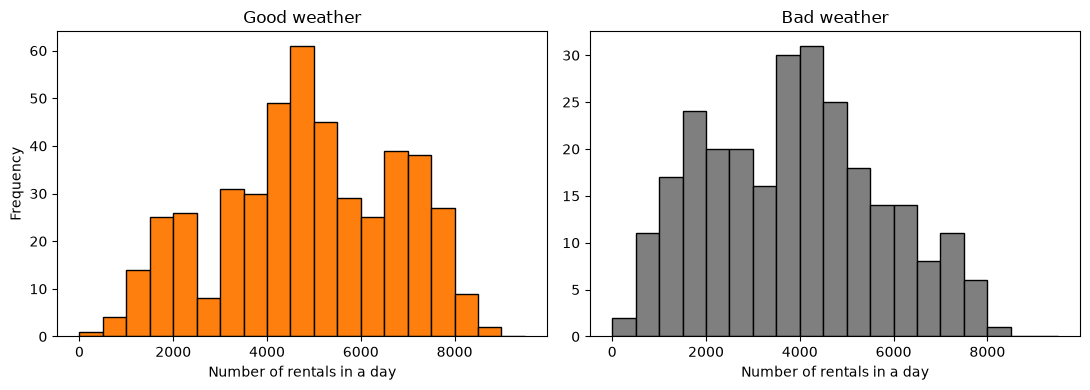

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(11,4), sharex=True)

max_val = bike["cnt"].max()
bins = np.arange(0, max_val + 1000, 500)

axes[0].hist(good, bins=bins, color="tab:orange", edgecolor="black")
axes[0].set_title("Good weather")
axes[1].hist(bad, bins=bins, color="tab:gray", edgecolor="black")
axes[1].set_title("Bad weather")

for ax in axes:
    ax.set_xlabel("Number of rentals in a day")
axes[0].set_ylabel("Frequency")
plt.tight_layout()
plt.show()

Neither histogram looks normal, but both sample sizes (463 and 268) are large, so the $t$-test can still be used. Next, the equal variance test.

In [57]:
print(f"Equal variance test p-value: {round(levene(good, bad).pvalue, 4)}")

Equal variance test p-value: 0.9992


The $p$-value of 0.9992 is large, so we assume equal variances and set `equal_var=True`. We test $H_0: \mu_X-\mu_Y=0$ against $H_1: \mu_X-\mu_Y\neq0$, with good weather as $X$.

In [58]:
result = ttest_ind(good, bad, equal_var=True, alternative="two-sided")

print(f"Test statistic: {round(result.statistic, 4)}")
print(f"df: {result.df}")
print(f"p-value: {result.pvalue}")
ci = result.confidence_interval(0.95)
print(f"95% CI for mu_X - mu_Y: ({round(ci.low, 2)}, {round(ci.high, 2)})")

Test statistic: 7.0568
df: 729.0
p-value: 3.971136385161276e-12
95% CI for mu_X - mu_Y: (733.25, 1298.48)


We get $T=7.0568$, $df=463+268-2=729$, a $p$-value of $3.971\times10^{-12}$, and the 95% CI of $(733.25, 1298.48)$. We reject $H_0$, and since both ends of the CI for $\mu_X-\mu_Y$ are positive, rental counts are higher on good-weather days.

To see where the test statistic comes from, we can compute the pooled variance $s_P^2=\frac{(n_1-1)s_X^2+(n_2-1)s_Y^2}{n_1+n_2-2}$ ourselves.

In [59]:
n1 = len(good)
n2 = len(bad)
var_x = np.var(good, ddof=1)
var_y = np.var(bad, ddof=1)

sp2 = ((n1-1)*var_x+(n2-1)*var_y)/(n1+n2-2) #pooled variance
se = np.sqrt(sp2)*np.sqrt(1/n1+1/n2)
T = (np.mean(good)-np.mean(bad))/se

print(f"Test statistic by formula: {round(T, 4)}")
print(f"p-value by formula: {2*t.sf(abs(T), df=n1+n2-2)}")

Test statistic by formula: 7.0568
p-value by formula: 3.971136385161276e-12


### HDB resale flats example (unequal variances)

The dataset `hdb_2017_now.csv` from data.gov.sg contains HDB resale transactions. We test whether the average price of 5-room flats is higher than that of 4-room flats, using the columns `flat_type` and `resale_price`.

In [60]:
hdb = pd.read_csv("../data/hdb_2017_now.csv")

five_room = hdb.loc[hdb["flat_type"] == "5 ROOM", "resale_price"]
four_room = hdb.loc[hdb["flat_type"] == "4 ROOM", "resale_price"]

print(f"5-room: n = {len(five_room)}, mean = {round(np.mean(five_room))}, SD = {round(np.std(five_room, ddof=1))}")
print(f"4-room: n = {len(four_room)}, mean = {round(np.mean(four_room))}, SD = {round(np.std(four_room, ddof=1))}")

print(f"Equal variance test p-value: {levene(five_room, four_room).pvalue}")

5-room: n = 24978, mean = 539365, SD = 148722
4-room: n = 41182, mean = 443363, SD = 122255
Equal variance test p-value: 5.7829039501237e-202


Both samples are very large, so normality is not a concern even though both histograms are right-skewed. The equal variance test has a $p$-value of practically 0, so we conclude that the variances are not equal and set `equal_var=False`. With $\mu_5$ as $\mu_X$, the hypotheses are $H_0: \mu_5-\mu_4=0$ against $H_1: \mu_5-\mu_4>0$, so we use `alternative="greater"` with `five_room` first.

In [61]:
result = ttest_ind(five_room, four_room, equal_var=False, alternative="greater")

print(f"Test statistic: {round(result.statistic, 2)}")
print(f"df: {round(result.df, 2)}")
print(f"p-value: {result.pvalue}")

Test statistic: 85.92
df: 45056.25
p-value: 0.0


These match the lecture, with $T=85.9$ and $df\approx45056$. The $df$ is not a whole number, since it comes from a more complicated formula, which is why the lecture relies on software for it. The $p$-value is so small that Python displays it as 0.0. We reject $H_0$ and conclude that 5-room resale flats have a higher average price than 4-room resale flats.

## Comparing two groups: dependent samples using `ttest_rel`

For dependent (paired) samples, we take the difference of each matched pair and carry out a one-sample $t$-test on the differences, with $H_0: \mu=0$.

### Reaction time example

The dataset `cellphone_reaction.csv` contains the reaction times (in milliseconds) of 32 drivers, each tested twice: once while talking on the phone (column `Yes`) and once while listening to the radio (column `No`). The first column of the file is just a row number, so we use `index_col=0` to make it the index instead of a column. We define $D=\text{Yes}-\text{No}$ and test $H_0: \mu=0$ against $H_1: \mu>0$ at $\alpha=0.01$.

In [62]:
reaction = pd.read_csv("../data/cellphone_reaction.csv", index_col=0)
print(reaction.head())

diff = reaction["Yes"]-reaction["No"] #the difference for each driver
print(f"n: {len(diff)}")
print(f"Mean difference: {round(np.mean(diff), 3)}")
print(f"SD of differences: {round(np.std(diff, ddof=1), 4)}")

    No  Yes
1  604  636
2  556  623
3  540  615
4  522  672
5  459  601
n: 32
Mean difference: 50.625
SD of differences: 52.4858


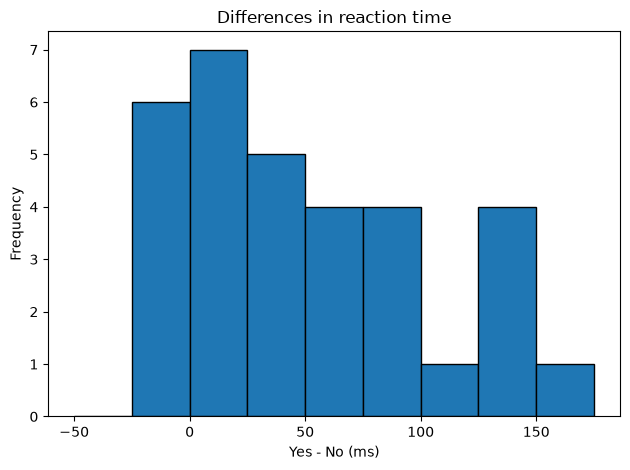

In [63]:
max_val = diff.max()
bins = np.arange(-50, max_val + 50, 25)

plt.figure()
plt.hist(diff, bins=bins, color="tab:blue", edgecolor="black")
plt.xlabel("Yes - No (ms)")
plt.ylabel("Frequency")
plt.title("Differences in reaction time")
plt.tight_layout()
plt.show()

The histogram of differences is not strongly skewed, and with $n=32$ we do not need to worry about normality.

The function `ttest_rel(x, y)`, where "rel" stands for related samples, carries out the paired $t$-test. It tests the mean of `x - y`, so the order matters. We compare it with `ttest_1samp` on the differences.

In [64]:
result_rel = ttest_rel(reaction["Yes"], reaction["No"], alternative="greater")
result_one = ttest_1samp(diff, popmean=0, alternative="greater") #the same test

print(f"ttest_rel: statistic = {round(result_rel.statistic, 4)}, p-value = {result_rel.pvalue}")
print(f"ttest_1samp on differences: statistic = {round(result_one.statistic, 4)}, p-value = {result_one.pvalue}")

ttest_rel: statistic = 5.4563, p-value = 2.901702659056481e-06
ttest_1samp on differences: statistic = 5.4563, p-value = 2.901702659056481e-06


Both lines give exactly the same result, $T=5.4563$ with $df=31$, which shows that a paired $t$-test is just a one-sample $t$-test on the differences. The $p$-value is far below 0.01, so reaction time is significantly slower when using a phone.

We also want to find the 99% CI for the mean difference. Since this is a CI for a single mean, we use the result of the two-sided one-sample test.

In [65]:
ci = ttest_1samp(diff, popmean=0).confidence_interval(0.99)
print(f"99% CI: ({round(ci.low, 3)}, {round(ci.high, 3)})")

99% CI: (25.165, 76.085)


With (25.165, 76.085), both ends are positive, so we are 99% confident that phone usage slows down reaction time.

We use the two-sided test here because a one-sided test, such as `alternative="greater"`, gives a one-sided interval with an upper bound of infinity.

### Caution: paired data must not be analysed as independent

What if we wrongly treat the two columns as independent samples?

In [66]:
result_wrong = ttest_ind(reaction["Yes"], reaction["No"], alternative="greater")
print(f"Wrong (independent) test: p-value = {round(result_wrong.pvalue, 4)}")

Wrong (independent) test: p-value = 0.0064


The $p$-value is now about 0.006, over 2000 times larger than before. Reaction times vary a lot from one driver to another (driver 28 is much slower than everyone else in both conditions), and the independent-samples test cannot remove this variation. The paired test compares each driver with themselves, so it detects the effect of the phone far more clearly. Always check how the data were collected before choosing the test.

## Checking normality

### QQ plot by hand

A QQ plot compares the standardized sample values with the quantiles of $N(0,1)$. We use a small sample of 10 values, $(14,13,1,20,7,14,2,19,8,10)$. First, we standardize and sort the values. Then we find the theoretical quantiles at probabilities $0.05, 0.15, \dots, 0.95$, created with `np.arange(0.05, 1, 0.1)`.

In [67]:
x = np.array([14,13,1,20,7,14,2,19,8,10])

z_scores = (x-np.mean(x))/np.std(x, ddof=1) #standardize
print(np.round(z_scores, 2))

sample_q = np.sort(z_scores) #observed quantiles
theory_q = norm.ppf(np.arange(0.05, 1, 0.1)) #expected quantiles
print(np.round(sample_q, 2))
print(np.round(theory_q, 2))

[ 0.5   0.34 -1.52  1.43 -0.59  0.5  -1.37  1.27 -0.43 -0.12]
[-1.52 -1.37 -0.59 -0.43 -0.12  0.34  0.5   0.5   1.27  1.43]
[-1.64 -1.04 -0.67 -0.39 -0.13  0.13  0.39  0.67  1.04  1.64]


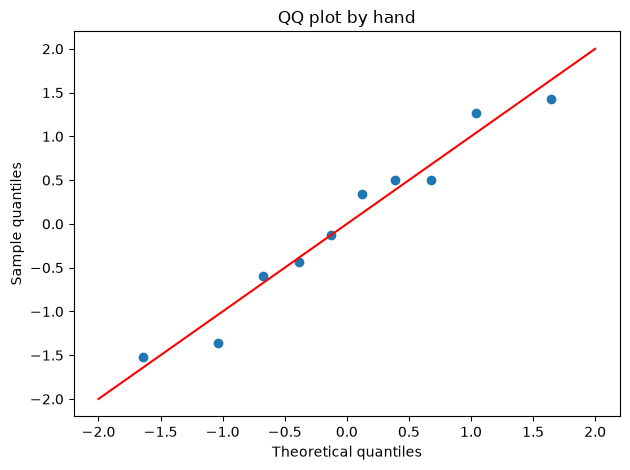

In [68]:
plt.figure()
plt.scatter(theory_q, sample_q, color="tab:blue")
plt.plot([-2,2], [-2,2], color="red") #the straight line y = x
plt.xlabel("Theoretical quantiles")
plt.ylabel("Sample quantiles")
plt.title("QQ plot by hand")
plt.tight_layout()
plt.show()

### QQ plot with probplot

The function `probplot(data, plot=plt)` draws a QQ plot for us, including the straight reference line. It uses the raw values on the vertical axis rather than standardized ones, but the shape is read in the same way: points close to the line suggest a normal distribution.

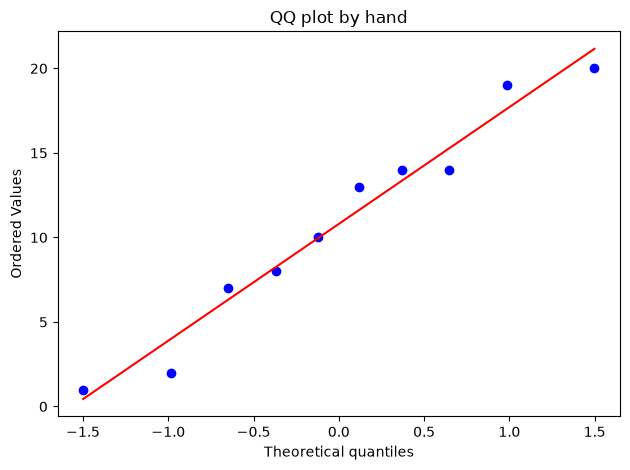

In [69]:
plt.figure()
probplot(x, plot=plt)
plt.title("QQ plot by hand")
plt.tight_layout()
plt.show()

### Gentoo penguins example (checking normality)

Previously, the histogram of the penguins' bill lengths was hard to judge, so we look at the histogram and the QQ plot side by side.

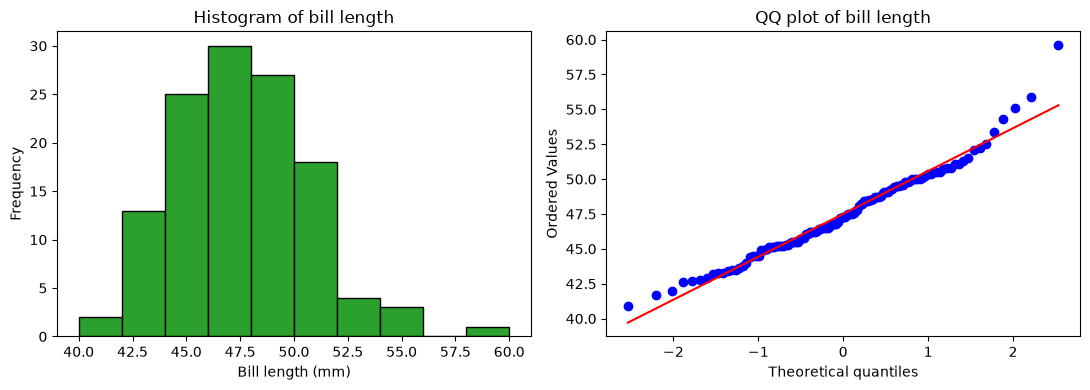

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))

max_val = length.max()
bins = np.arange(40, max_val + 2, 2)

axes[0].hist(length, bins=bins, color="tab:green", edgecolor="black")
axes[0].set_xlabel("Bill length (mm)")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Histogram of bill length")

probplot(length, plot=axes[1])
axes[1].set_title("QQ plot of bill length")

plt.tight_layout()
plt.show()

Most of the points lie close to the line, but both ends sit above it. The right tail is above the line, so it is longer than normal, and the left tail is above the line, so it is shorter than normal. This suggests a slight right skew, which is also visible in the histogram (including the largest value of 59.6 mm). Some may still call this approximately normal while others may not, which is why a test is useful.

### Shapiro-Wilk test

The Shapiro-Wilk test has $H_0$: the sample is from a normal distribution, against $H_1$: it is not. We hope for a large $p$-value. In Python, we use `shapiro(data)`.

In [71]:
result_sw = shapiro(length)
print(f"Test statistic: {round(result_sw.statistic, 4)}")
print(f"p-value: {round(result_sw.pvalue, 4)}")

for alpha in [0.01, 0.05]:
    if result_sw.pvalue <= alpha:
        print(f"alpha = {alpha}: reject H0, the data are not from a normal distribution")
    else:
        print(f"alpha = {alpha}: do not reject H0, the data can be treated as normal")

Test statistic: 0.9727
p-value: 0.0135
alpha = 0.01: do not reject H0, the data can be treated as normal
alpha = 0.05: reject H0, the data are not from a normal distribution


The test statistic is 0.9727 and $p$-value is 0.0135. Since the $p$-value lies between the two common significance levels, the conclusion depends on $\alpha$: we do not reject normality at $\alpha=0.01$, but we do at $\alpha=0.05$.

For the one-sample $t$-test earlier, this does not cause a problem. With $n=123$, the sample is large, and the $t$-test is robust to the normality assumption. Remember also that the Shapiro-Wilk test is meant for small samples, since with large samples it can reject normality even for minor departures that do not matter in practice.

## Summary of Python tools in this topic

| Task | Code |
|---|---|
| $p$-value from $Z$ (right, left, two-sided) | `norm.sf(z)`, `norm.cdf(z)`, `2*norm.sf(abs(z))` |
| $p$-value from $T$ (right, left, two-sided) | `t.sf(T, df)`, `t.cdf(T, df)`, `2*t.sf(abs(T), df)` |
| One-sample $t$-test | `ttest_1samp(data, popmean=mu0, alternative=...)` |
| Equal variance test | `levene(x, y)` |
| Two independent samples | `ttest_ind(x, y, equal_var=True or False, alternative=...)` |
| Paired samples | `ttest_rel(x, y, alternative=...)` |
| CI from a $t$-test result | `result.confidence_interval(0.95)` |
| QQ plot | `probplot(data, plot=plt)` |
| Shapiro-Wilk test | `shapiro(data)` |

The `alternative` argument is `"two-sided"` (the default), `"greater"` or `"less"`, and it always refers to the first sample minus the second (or the data minus `popmean`).